---
title: Scaling Decision Analysis with Hyperbolic Trade Space Identification
abstract: |
  A trade study must produce an answer and a justification an accountable executive can follow.
  Principal component analysis (PCA) is trusted as reproducible and interpretable, and explains
  variance. We explain tensions. A fitted posynomial reference surface models
  the data underlying the table, not the Pareto boundary, and gives the data a coordinate system;
  the table and its reading are views of that model. It is fitted to the outer edge of the data, not
  through its middle: a soft support that a few designs may exceed, not a regression. A reversible chart separates a design's position along
  the surface from its energy differential: its level relative to the surface, by analogy with a
  potential, not a physical energy. Each monomial term (a product of powers of the metrics) reports
  its contending metrics, an n-lemma (by analogy with dilemma and trilemma), with elasticities:
  the percentage of one metric given up per percentage gained in another. Modelling a single
  n-lemma fits a monomial, which transforms into a convex program and is solved directly; when
  several trade-offs are active at once the model is a posynomial, compatible with generalized
  geometric programming (GGP); any kernel that keeps that compatibility generalizes the method.
  Like PCA, our method is unsupervised feature engineering; the two answer different
  questions and compose, as when PCA is run on the chart. On a cubesat model coupling power, mass and attitude control, one term blends
  the subsystems' trade-offs into a single tension; two terms separate the contending sets.
---

In [1]:
import paper_paths  # puts the repository and examples/adcs on sys.path

paper_paths.inline_figures()

In [2]:
import case

study = case.load_study("primary")

In [3]:
fits = case.k_fits(study)

(sect-problem)=
## The decision problem

This paper is for readers deciding whether to rely on a trade study, checking the mathematics ({numref}`Section %s <sect-definitions>`, {ref}`Appendix B <appendix-b>`), or placing the method among prior methods ({numref}`Section %s <sect-prior-art>`, {ref}`Appendix G <appendix-g>`).

Decision analysis has two products: an answer, and a justification an accountable executive can follow and defend. It seeks responsible choice among conflicting objectives [@keeney1993decisions] and clear conversation with the decision-maker [@howard1988decision]. The justification is the hard product: the process turning much data into little must be recognized, reproducible, rigorous.

A trade study is a document: a grid, a table, a ranking by weighted criteria; surveys compare them [@baker2012survey]. The weights are human judgments, susceptible to bias in trade studies [@smith2007ameliorating; @chilli2026decision]. Systems engineering is moving from document-based [@henderson2021value] to model-based practice [@madni2018model]. But the computational alternatives are bespoke and opaque. To displace the document, a method must handle real data's scale, complexity and noise interpretably.

PCA reduces dimensionality and increases interpretability while minimizing information loss [@jolliffe2016principal]. But variance says where the data are free and nothing about trade-offs, which a decision-maker must know to defend a judgment.

Objectives may align in one region and oppose in another. The fitted reference surface ({prf:ref}`def-objects`), a posynomial fitted to the data underlying the table, gives them a coordinate system. The chart is a reversible rewriting of the metrics as a position along the surface and a level relative to it. Each monomial term, a piece of the surface and not a set of designs, names the metrics that contend on it with elasticities: an n-lemma (by analogy with dilemma and trilemma). The workflow has two uses: design optimization, the setting of multidisciplinary design analysis and optimization [@martins2013multidisciplinary; @martins2021engineering], and configuration management. In both, a configuration is evaluated into attributes whose trade-offs the fit reads.

**Contribution.** Scaling up trade studies with a reproducible method. On this case, with the number of designs and of metrics, dominance stops shortlisting: its nondominated set is the whole table.

In [4]:
from generate_findings import nondominated_sentence

nondominated_sentence(study)

'Of 2,134 feasible cubesat designs, the nondominated set (on the conditioned metrics, larger is better) holds 236 on 4 attributes (settling time, pointing error, control effort and total mass) and 2,134 on all 13 (counts that hold over five regenerations of the data under rounding-level perturbation; a number that moves over them is printed as a range, <a href="supporting-material/#sub-d-11" target="_self" style="color:inherit;text-decoration:underline">Appendix D.11</a>).'

**Main results**

1. With one term, the fitted reference surface is where the invariant value ({prf:ref}`def-invariant`), a weighted geometric mean of the metrics that doubles when every metric doubles ({prf:ref}`thm-invariant`), equals one; {numref}`Section %s <sect-methods>` fits it. It is not the Pareto boundary: every design's position and level are read from it through the chart ({prf:ref}`def-chart`), and each term's elasticities from its exponents ({prf:ref}`def-exchange`).
2. The one-term fit is a geometric program in the exponents ($x=e^{w}$), convex in $w$, so every minimizer is global, though uniqueness is not claimed ({prf:ref}`thm-kkt`, {prf:ref}`thm-convex`). Its exponents are elasticities and its chart is reversible ({prf:ref}`thm-elasticity`, {prf:ref}`thm-chart`).
3. With one term the posynomial extension is the monomial ({prf:ref}`thm-extension`), and a maximizer of V over a set of designs, the table included, is weakly Pareto-efficient ({prf:ref}`thm-pareto`).
4. The several-term fit is not convex in the terms ({prf:ref}`thm-soft`). It has three levels of guarantee, descent ({prf:ref}`thm-descent`), the term gap ({prf:ref}`lem-gap`) and local optimality with the cells held fixed ({prf:ref}`lem-margin`, {prf:ref}`prop-local`), and a stopping declaration, a paragraph of {numref}`Section %s <sect-results>` and not a numbered result. The second-order certificate of a strict local minimizer is for a soft fit ({prf:ref}`thm-certificate`).
5. The method and PCA compose: PCA run on the near-frontier chart reads the trade-offs the sampling exercised, a reading and not a result ({ref}`Appendix D.16 <sub-d-16>`).
6. Open: Q1 to Q4, four questions not established ({numref}`Section %s <sect-results>`), and the outer loop of the search, which may move inward on a step ({numref}`Section %s <sect-search>`).
7. On a cubesat model coupling power, mass and attitude control two terms hold different contending sets where one term merges them into one ({numref}`Section %s <sect-case-analysis>`: a numerical result, observed and not proved).

The method claims nothing as novel and does not replace PCA or Pareto analysis.

**Organization.** By depth: abstract and {numref}`Figure %s <fig-nlemma>`; headers and Main results; whole text (assuming multivariate calculus, linear algebra and convex optimization); {ref}`supporting material's appendices <appendix-a>`; repository and container ({numref}`Section %s <sect-reproducibility>`).

(sect-prior-art)=
## Prior art, by family

We claim no priority. {numref}`Table %s <tab-families-1>` lists the families and what we share with each. {ref}`Appendix G <appendix-g>` is the larger register and says for every entry how this work differs.

In [5]:
from generate_prior_art import family_table

family_table()

Family and sources,Produces,Shares,Differs
Pareto and multiobjective optimizationMiettinen 1999; Ehrgott 2005; Zitzler and Thiele 1999; Deb et al. 2002,Returns a nondominated set of designs,A maximizer of a weighted geometric mean with positive exponents is Pareto-efficient,This work returns a coordinate system and exponents
Data envelopment analysis (DEA)Charnes et al. 1978; Banker et al. 1984; Andersen and Petersen 1993; Färe et al. 1994; Allen et al. 1997; Dyson et al. 2001,Evaluates the relative efficiency of each decision-making unit,"A one-sided envelope of the data, a score per unit","This work fits global exponents per term, not per-unit weights"
Production and distance functionsCobb and Douglas 1928; Shephard 1970; Färe and Primont 1995; Farrell 1957,"The Cobb-Douglas production form, and the Shephard distance function",the constant-returns Cobb-Douglas form,This work takes attributes in place of inputs
Deterministic and stochastic frontiersAigner and Chu 1968; Afriat 1972; Richmond 1974; Greene 1980; Aigner et al. 1977; Battese 1992,Estimates frontier production functions,A one-sided criterion on log-linear residuals,This work uses a smooth soft maximum over a simplex-constrained geometric mean
Principal component analysis (PCA)Jolliffe and Cadima 2016,Finds uncorrelated components that successively maximize variance,an unsupervised summary in a few directions,"This work's criterion is a one-sided soft maximum, not variance"
Compositional and log-ratio PCAAitchison 1983; Aitchison 1986; Egozcue et al. 2003,PCA of compositional data,an isometric logratio chart,This work's criterion is one-sided; its weights lie on the simplex
Geometric programming and max-affine fittingBoyd et al. 2007; Hoburg and Abbeel 2014; Hoburg et al. 2016; Magnani and Boyd 2009; Candès et al. 2008,Geometric programming with generalized posynomials,The K > 1 refit scheme and the sparsity option,"This work fits an envelope, the one-sided boundary of the data"
Kernel PCASchölkopf et al. 1998,PCA in an implicit feature space,the feature-engineering kin of the kernel direction,This work builds no kernel and maximizes no variance
HoroPCA (PCA in hyperbolic space)Chami et al. 2021,PCA components carried into hyperbolic space,The closest existing analog in setting,"This work estimates a one-sided edge, not a variance over frames"
Multidisciplinary design analysis and optimization (MDAO)Sobieszczanski-Sobieski and Haftka 1997; Martins and Lambe 2013; Lambe and Martins 2012; Gray et al. 2019; Martins and Ning 2021,solves the coupled system inside an optimizer,a configuration is evaluated by coupled disciplinary models into attributes,This work fits the table the evaluations leave behind


::::{table} The families of prior art closest to this work: what each produces, what it shares with this work, how this work differs, and the sources.
:label: tab-families-1
:::{embed} #tab-families
:remove-input: true
:::
::::

[@miettinen1999nonlinear; @ehrgott2005multicriteria; @zitzler1999multiobjective; @deb2002fast; @charnes1978measuring; @banker1984some; @andersen1993procedure; @fare1994productivity; @allen1997weights; @dyson2001pitfalls; @charnes1982multiplicative; @charnes1983invariant; @banker1986piecewise; @fare1985measurement; @cobb1928theory; @shephard1970theory; @fare1995multi; @farrell1957measurement; @aigner1968estimating; @afriat1972efficiency; @richmond1974estimating; @greene1980maximum; @aigner1977formulation; @battese1992frontier; @jolliffe2016principal; @aitchison1983principal; @aitchison1986statistical; @egozcue2003isometric; @boyd2007tutorial; @hoburg2014geometric; @hoburg2016data; @magnani2009convex; @candes2008enhancing; @schoelkopf1998nonlinear; @chami2021horopca; @foellmer2026entropic; @ahmadijavid2012entropic; @sobieszczanski1997multidisciplinary; @martins2013multidisciplinary; @lambe2012extensions; @gray2019openmdao; @martins2021engineering; @ross2004multi; @ross2005tradespace; @ross2010revisiting; @stump2003design; @simpson2008visual; @stump2009visual; @spero2014tradespace; @howard1988decision; @keeney1993decisions; @baker2012survey; @parnell2016trade; @hirshorn2017nasa; @chilli2026decision; @smith2007ameliorating; @parnell2021system; @madni2018model; @henderson2021value]

**Pareto methods.** Pareto methods return a nondominated set and find its members by scalarization, for example the weighting method [@miettinen1999nonlinear; @ehrgott2005multicriteria]; evolutionary algorithms generate such sets [@zitzler1999multiobjective; @deb2002fast]. A nondominated set says which designs survive. The fit says what trades against what. Dominance is a hard comparison that stops discriminating, on this case, as metrics are added. The two meet in one result: a maximizer of V with positive exponents is Pareto-efficient ({prf:ref}`thm-pareto`). **Open.** Which part of the Pareto boundary the terms reach is our reading: the theorem gives efficiency of a maximizer, not the converse.

**Data envelopment analysis.** DEA is the closer relative [@charnes1978measuring; @banker1984some]. It scores each unit against the data by mathematical programming, with weights obtained from the data rather than set in advance [@banker1984some]. We fit one exponent vector per term, a global named structure, where DEA obtains weights unit by unit. Our surface is piecewise log-linear, with constant elasticities within a term. Our boundary is a soft maximum with a temperature, not a boundary set by extreme units. The title's "hyperbolic" is defined in {numref}`Section %s <sect-definitions>` and {ref}`Appendix A <appendix-a>`.

**HoroPCA.** HoroPCA [@chami2021horopca] is the closest existing analog in setting: unsupervised, with a table in and coordinates out. It is the farthest in what is estimated: it extends the components of PCA to hyperbolic space with horospherical projections, maximizing a variance. This work fits the one-sided edge of a table and is not a PCA of any kind. We borrow that setting and the estimator interface of scikit-learn, and use PCA as a downstream step ({ref}`Appendix D.16 <sub-d-16>`). In a prospectively specified test, on an embedding of ours, the authors' code, at its defaults and one direction at a time, recovered planted exponents only where they were the direction of largest spread; the tables are clean, so it demonstrates a mechanism and does not measure how often recovery succeeds ({ref}`Appendix H <appendix-h>`).

**Lineage.** The weighted geometric mean with exponents summing to one has the constant-returns Cobb-Douglas form [@cobb1928theory]. Reading V as the factor that scales a design to the boundary is our distance-function reading, after Shephard's characterization of a technology by its distance function [@shephard1970theory; @fare1995multi; @farrell1957measurement]. The family of one-sided fits, frontier estimation by programming, corrected least squares and one-sided error, is reviewed in [@battese1992frontier] after [@aigner1968estimating; @afriat1972efficiency; @aigner1977formulation]. The chart is in the spirit of log-ratio coordinates for compositional data [@aitchison1983principal; @egozcue2003isometric]. The model class and refit scheme come from geometric programming and max-affine fitting [@boyd2007tutorial; @hoburg2016data; @magnani2009convex]; the soft maximum is an entropic risk functional [@foellmer2026entropic]. Kernel PCA is the feature-engineering relative of the kernel direction in {numref}`Section %s <sect-discussion>` [@schoelkopf1998nonlinear]. Combining these pieces in one estimator is our design. We did not find the combination in the sources reviewed, which {ref}`Appendix G <appendix-g>` lists.

(sect-notation)=
## Preliminaries and notation

Mathematical notation follows Boyd and Vandenberghe [@boyd2004convex] and estimator terms follow the scikit-learn documentation [@pedregosa2011scikit; @buitinck2013api]; {ref}`Appendix A <appendix-a>` is the full register of symbols and terms. The package is the scikit-learn estimator of {numref}`Section %s <sect-methods>` and {ref}`Appendix F <appendix-f>`.

**The pipeline.** A configuration $c$ (the design variables) is evaluated into attributes $a$ (the evaluation outcomes), which the analyst conditions into metrics $m$: strictly positive and larger is better. Stage 1 evaluates, and **the evaluation is a black box to the method: a simulator behind a system model, a physical test, or a human assessment.** The cubesat model of {numref}`Section %s <sect-case-construction>` is one instance behind that abstraction, not part of the method. Stage 2 is conditioning, the analyst's step, done with scikit-learn tools ({numref}`Section %s <sect-methods>`). Stages 3 and 4, identification and analysis, are the method. With $N$ designs and $d$ metrics, $M\in\mathbb{R}^{N\times d}_{>0}$ is the table of metrics, $U=\log M$ has rows $u_i$, and $\Delta$ is the probability simplex in $\mathbb{R}^d$.

**Assumptions.** A1: metrics are strictly positive. A2: exponents lie on the simplex. A3: $\tau>0$. A4: conditioning is log-affine and invertible. A5: noise, where used, is independent $N(0,\sigma^2)$ in log space. A6: $\kappa>0$ and each term's exponents lie on the simplex. A7: the chart's basis is orthonormal and sums to zero. A8: the rows split into nonempty cells, one per term. A9: each row's noise is Gaussian with mean zero and one covariance $\Sigma$. A10: an attribute's measurement error is multiplicative, log-normal and independent across attributes; L18 maps it to the noise of A9. A3 and A6 are for finite values; $\tau=\infty$ and $\kappa=\infty$ are the exact limits, the maximum, named where they are used. {numref}`Section %s <sect-methods>` adds the regularity conditions R1, R2 and R3.

**Map and territory.** All models are wrong, some are useful, and a model is useful for a specific purpose in a specific situation; here the purpose is improving trade studies. The formal results are properties of mathematical objects, conditioned on assumptions that we cannot certify for a given table of designs, and the implementation approximates those objects numerically. Results are read in light of the gaps ledger in {ref}`Appendix E <appendix-e>`. It records, for each place where the map and the territory part, the assumption that bridges it, what cannot be proved and the evidence on sensitivity.

**Words.** A posynomial is a sum of monomial terms, each a positive constant times a product of powers of the metrics. The fitted reference surface is made of trade-offs, each monomial term one piece; at $\kappa=\infty$ the pieces are flat in log space, and a finite $\kappa$ rounds them at the seams. Three objects carry the word frontier ({prf:ref}`def-objects`).

:::{prf:definition} Three objects
:label: def-objects
The fitted reference surface is $V=1$ at finite $\tau$ (the fit temperature, {prf:ref}`def-temperature`), where the posynomial equals one; some designs lie beyond it. The supporting envelope is the $\tau=\infty$ fit, which none of the rows of the design table exceeds. The Pareto boundary is the nondominated set of the attainable set (all realisable designs), a property of the system.
:::

(sect-definitions)=
## Definitions

The invariant value $V$ is a weighted geometric mean of the metrics; doubling every metric doubles it. It stays the same along a trade-off, hence invariant. In two metrics its level curves are $m_1^{w_1}m_2^{w_2}=\text{const}$; when $w_1=w_2$ they are the rectangular hyperbola $m_1m_2=\text{const}$, the title's word.

:::{prf:definition} Invariant form
:label: def-invariant
For $w\in\Delta$ and the reach $\beta$ (how far the data extend along $w$, {prf:ref}`def-reach`), $V(m)=e^{-\beta}\prod_j m_j^{w_j}$: the weighted geometric mean, scaled so that $V=1$ on the fitted reference surface; $\log V=w\cdot u-\beta$.
:::

By analogy with a potential, designs of equal $V$ stand at the same level. $\log V$, the energy differential, is a design's level relative to the fitted reference surface $V=1$: negative inside, positive beyond. A difference of levels is the same along every path between two designs. It is neither a physical energy nor a Euclidean distance.

Where several trade-offs are active at once, the model is a sum of such terms, one per trade-off.

:::{prf:definition} Posynomial
:label: def-posynomial
$V_K(m)=\big(\sum_{k=1}^{K}e^{-\kappa\beta_k}\prod_j m_j^{\kappa w_{kj}}\big)^{1/\kappa}$ with $w_k\in\Delta$. $V_K$ is the $1/\kappa$ power of a posynomial, a sum of monomials ({prf:ref}`thm-extension`), the one in brackets; $e^{\kappa\Phi_K}$ is that posynomial, where $\Phi_K(u)=\frac1\kappa\log\sum_k e^{\kappa(w_k\cdot u-\beta_k)}$ is the logarithm of $V_K$. Term aggregation: the formula is the sum. The package's mean ($\kappa=\infty$: the maximum) subtracts the constant $(\log K)/\kappa$ from every level and changes neither exponents nor minimizers. For each term, the designs whose largest term it is form its cell. The fits of record, every $K=2$ figure included, are sharp ($\kappa=\infty$).
:::

Two temperatures say how soft each maximum is, over designs and over terms; at infinity each is exact.

:::{prf:definition} Temperatures and band
:label: def-temperature
The fit temperature $\tau>0$ sets how hard the maximum is ($\tau=\infty$ is exact); the term temperature $\kappa>0$ how sharply terms meet. The near-frontier band is $|\log V|<1/\tau$. The fit weighs every design in its soft maximum, and one inside the band weighs within a factor $e$ of the weight a design on the surface would have ({ref}`Appendix B, L5.25 <appendix-b>`), which states the bound on the closed band $|\log V|\le1/\tau$; the band here is the open one, as the code counts it.
:::

:::{prf:definition} The chart
:label: def-chart
$Z=Bu$, with $B$ of size $(d-1)\times d$, $BB^\top=I$ and $B\mathbf 1=0$, is the position along the surface, free of overall scale. $(Z,\log V)$ is the chart, a reversible rewriting of the metrics; $\log V$ is the energy differential (level offset).
:::

:::{prf:definition} The n-lemma
:label: def-nlemma
The contending set of term $k$ is the support (exponents above $10^{-9}$) of the exact-maximum ($\tau=\infty$) fit to the term's cell, centred on the cell's mean log-metric: $f_k$ of equation (2) on the cell's rows alone. Its size $\nu_k$ names it. It is found, not assumed. The exact-maximum support is checked under rounding-level jitter ({ref}`Appendix D.11 <sub-d-11>`); at $K=1$ its optimum is one point on both regimes, and for several terms the solver resolves a tie at the exact maximum (gap G-10). Three thresholds read an exponent, each a convention: at or below $10^{-12}$ it is numerically zero, not mathematically so; above $10^{-9}$ in the exact-maximum fit it is in the contending set; above $10^{-3}$ at the fit temperature it participates and carries an elasticity. They nest in size, and the last two read different fits. In the reading, the contending set names the n-lemma, the exponents at the fit temperature give the elasticities, and a member below the participation threshold ({numref}`Section %s <sect-methods>`) contends in the limit and carries no elasticity at the fit temperature.
:::


:::{figure} figures/fig-nlemma.png
:label: fig-nlemma
The n-lemma on the simplex, for three metrics (a synthetic table with three planted terms, which its generator builds in). The three dots are the terms of one fitted posynomial, each one piece of the fitted reference surface; a term's exponent vector at the fit temperature is a point of the triangle. The face names the term's n-lemma. It is read from the term's contending set ({prf:ref}`def-nlemma`: the exponents above $10^{-9}$ in the exact-maximum fit to its cell), and the point drawn, from the fit temperature, may lie a little inside that face. A corner, one metric contends alone; an edge, a dilemma of the two metrics at its ends; the interior, a trilemma.
:::

*Shows:* each term's exponent vector as a point of the simplex, in the face that names its n-lemma. *Does not show:* designs, their levels or the surface; with more than three metrics, anything beyond the three drawn. *Good for:* reading by eye how many and which metrics contend in a term.

:::{prf:definition} Reach and share
:label: def-reach
The reach $\beta_k$ is how far the data extend in direction $w_k$. It is the soft maximum of their scores along it (a design's score along $w_k$ is $w_k\cdot u$), the largest score at $\tau=\infty$. The term share is the fraction of near-frontier designs in the cell of term $k$; it shows which terms carry most of the near-frontier designs and depends on the band. Terms are numbered by share, largest first (ties by cell size, then by the first exponent).
:::

:::{prf:definition} Elasticity
:label: def-exchange
Along term $k$, for $i\neq j$ with $w_{kj}>0$, $\mathrm{d}\log m_j/\mathrm{d}\log m_i=-w_{ki}/w_{kj}$, the percent change of $j$ per percent change of $i$.
:::

:::{prf:definition} Ascent direction
:label: def-ascent
On term $k$ the tangent space $\{v:w_k\cdot v=0\}$ trades contending metrics at constant $V$; the normal $w_k$, the ascent direction, is the gradient of $\log V$ in $u$.
:::

(sect-methods)=
## Methods

**Conditions of the theory.** R1: at the exact-maximum ($\tau=\infty$) fit, with $p$ some optimal dual weight vector, the balanced point $U^\top p$ lies in the relative interior of a facet of the convex hull of the rows, whose normal is positive; the components of $U^\top p$ on the support of $w$ are equal ({prf:ref}`thm-kkt`). The facet-normal reading of {prf:ref}`thm-kkt` and the positive exponents of {prf:ref}`thm-elasticity` rest on it. R2 ($K\ge2$): the assignment margin $\gamma=\min_i[s_{i,k(i)}-\max_{k\neq k(i)}s_{ik}]$ is positive, with $s_{ik}=w_k\cdot u_i-\beta_k$ the score of design $i$ on term $k$, its level against that term alone. R2 is used by {prf:ref}`lem-margin`, {prf:ref}`prop-local` and the stopping declaration. R3: at the clean fit (the fit of the noise-free table) the zero exponents have gradient strictly above the nonzero exponents' common value, and $C=\mathrm{Cov}_p(u)$, the covariance of the log-metrics under the softmax weights $p=\mathrm{softmax}(\tau Uw)$ at the fit, is positive definite on the sum-zero vectors that vanish where $w$ does. <!-- vocab-exempt: facet -->

**The model.** At $K=1$ the fitted reference surface is the unit level set of $V$. The fit asks for the nonnegative combination of log-metrics along which the data have the smallest upper extent, under an entropic soft maximum. With scores $s_i=w\cdot u_i$,
$$
\begin{aligned}
J_\tau(w)&=\tfrac1\tau\log\Big(\tfrac1N\sum_{i}e^{\tau w\cdot u_i}\Big),\\
w^*&\in\arg\min_{w\in\Delta}J_\tau(w),\quad\beta=J_\tau(w^*).
\end{aligned}
$$
$\beta$ is the log-mean-exp, not the unnormalized log-sum-exp ({prf:ref}`thm-lme`): the factor $1/N$ leaves the minimizer unchanged and moves the reach by $(\log N)/\tau$. At $\tau=\infty$ the fit is a linear program. At finite $\tau$ one term is a geometric program in $x=e^{w}$, convex in $w$ ({ref}`Appendix B, supporting material, L4.14 to L4.24 <appendix-b>`). $V_K$ is a generalized posynomial, the term maximum at the default $\kappa=\infty$ [@boyd2007tutorial]. The several-term fit alternates weights with one program for all terms ({prf:ref}`thm-soft`). $\tau$ puts a target fraction of designs above $V=1$: about a tenth, by convention (10 percent here), which keeps one extreme design from setting the surface. Halving or doubling that fraction leaves the contending sets unchanged, and a different scaler does not ({ref}`Appendix D.5 <sub-d-5>`).

**Conditioning (stage 2).** The theory asks conditioning to be log-affine per metric, $\log m_j=\alpha_j\log(a_j+s_j)+b_j$ with $\alpha_j\neq0$ (the lemma scripts write the shift and the attribute with other letters: {ref}`Appendix A <appendix-a>`). A negative $\alpha_j$ marks smaller-is-better; the shift $s_j$ places the origin; a scaler (scikit-learn's word for a per-metric rescaling) equalizes log-spread so one $\tau$ serves every metric. These choices define the question. Rescaling one metric changes which term is tangent (touches the edge of the data there), so a stable fitted direction answers that question and is not a context-free discovery. A1 is the model's hypothesis; the package tolerates a zero metric by leaving that row out of the fit, without a warning, and $N$ counts the other rows. The case has none, since feasibility requires positive attributes. Negative values are rejected, and the pull-back to attribute units is exact ({prf:ref}`thm-pullback`). An exponent above the participation threshold ($10^{-3}$) participates ({prf:ref}`def-nlemma` sets the three thresholds side by side). The case's conditioning rule is {ref}`Appendix C.4 <sub-c-4>`'s; the documentation's Conditioning page is the guide.

**The estimator.** The fit is a scikit-learn transformer of the decomposition family: `fit` identifies exponents and reaches, `transform` returns the chart, `inverse_transform` reverses it, `score_samples` returns the energy differential. It has no `predict`: prediction composes a supervised regressor with the chart.

**Simplifying assumptions.** (i) *One term at $K=1$:* constant elasticities; $K>1$ is built. (ii) *Sharp weights by default, soft on request:* terms are fitted at $\kappa=\infty$ with kinks on the seams, where terms meet. For given terms a finite $\kappa$ moves the score by at most $(\log K)/\kappa$ ({prf:ref}`thm-extension`) and, by construction, leaves the terms unchanged. Fitting at a finite $\kappa$ is the soft fit of {numref}`Section %s <sect-results>`, which does change them. (iii) *The analyst chooses $K$:* a modelling choice, as the number of retained components is for PCA. (iv) *Small $K$:* the case is read at $K=2$, the value the package's checks point to ({ref}`Appendix D.15 <sub-d-15>`); $K=3$ is certified too and adds a thin term. A small $K$ keeps each contending set readable. (v) *Log-affine conditioning:* it is exactly invertible ({prf:ref}`thm-pullback`) and stays inside geometric programming. (vi) *A log-convex surface:* $\Phi_K$ is convex in $u=\log m$, which is what log-convex means here; no $K$ represents non-log-convex structure.

(sect-results)=
## Results

**Derived** means proved from its hypotheses by a plain-SymPy script the tests run, at symbolic $d$, $N$ and $K$; a step that is an exact instance (a constructed example) says so. The sketch is the idea, the script the check. **Numerical** means observed and not proved. **Open** means not established. Whether the hypotheses suit a table is a human judgment ({numref}`Section %s <sect-discussion>`). The hypothesis codes are listed in {ref}`Appendix B <appendix-b>` and {ref}`Appendix E <appendix-e>`: A, the assumptions of {numref}`Section %s <sect-notation>`; R, the conditions of {numref}`Section %s <sect-methods>`; F, a fallback hypothesis a script declares because a step resisted symbolic simplification, such as that a maximum over finitely many terms is attained; and I, an inherited result of the literature.

(Ln) names a lemma script and its entry in {ref}`Appendix B <appendix-b>`.

### The fit and its geometry

The invariant value scales with the metrics (L1), and shifting every log-metric by a constant moves the reach by that constant and leaves the exponents unchanged (L2).

:::{prf:theorem} Homogeneity and the invariant form (L1)
:label: thm-invariant
**Derived.** *Hypotheses.* A1 (metrics positive), A2 (exponents on the simplex).

Here $V=\prod_jm_j^{w_j}$, the case $\beta=0$ of {prf:ref}`def-invariant`, which scales it by $e^{-\beta}$ so that $V=1$ on the fitted reference surface. For $\lambda>0$: $V(\lambda m)=\lambda V(m)$ and $V(m/V(m))=1$; $V(me^{-\beta})=e^{-\beta}V(m)$.
:::

:::{prf:proof} Sketch
A1 gives $V=\exp(w\cdot u)$; A2 turns scaling by $\lambda$ into the addition of $\log\lambda$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_01_homogeneity.py`, `verify`; {ref}`Appendix B, L1 <appendix-b>`.
:::

:::{prf:proposition} Uniform shift (L2)
:label: prop-shift
**Derived.** *Hypotheses.* A1, A2, A3; $w\in\Delta$.

$J_\tau(w;U+c)=J_\tau(w;U)+c$, $c$ added to every entry: $\beta$ moves by $c$ and the minimizers are unchanged.
:::

:::{prf:proof} Sketch
Weights summing to one shift every score by $c$, and the log-mean-exp is shift-equivariant.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_02_shift.py`, `verify`; {ref}`Appendix B, L2 <appendix-b>`.
:::

The one-term fit has simplex optimality conditions (L3), is convex (L4), and uses the log-mean-exp, which differs from the log-sum-exp by a constant (L5).

:::{prf:theorem} Gradient and the simplex KKT conditions (L3)
:label: thm-kkt
**Derived.** *Hypotheses.* A2, A3; $w$ minimizes $J_\tau$ on $\Delta$; for the facet-normal reading, $w_j>0$ for every $j$ at the fit temperature, taken on its own: R1 is a $\tau=\infty$ condition and does not give it ({ref}`Appendix B, L3.9 <appendix-b>`). <!-- vocab-exempt: facet -->

$\nabla J_\tau=U^\top p$, $p=\mathrm{softmax}(\tau Uw)$. With $g=\nabla J_\tau(w)$, $\lambda=w\cdot g$: $g_j\ge\lambda$ and $w_j(g_j-\lambda)=0$, so $U^\top p$ has equal components on the support of $w$. R1 is a statement about the exact-maximum ($\tau=\infty$) geometry; it does not imply that the finite-$\tau$ minimizer is interior.
:::

:::{prf:proof} Sketch
Differentiate the log-mean-exp. Active simplex constraints are affine with independent gradients (I10: first-order conditions).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_03_gradient_kkt.py`, `verify`; {ref}`Appendix B, L3 <appendix-b>`.
:::

:::{prf:theorem} Convexity of the fit (L4)
:label: thm-convex
**Derived.** *Hypotheses.* A1, A3 ($\tau$ finite).

with $p$ as above, $\frac{d^2}{dt^2}J_\tau(w+tv)|_0=\tau\mathrm{Var}_p(v\cdot u)\ge0$: $J_\tau$ is convex, not claimed strictly.
:::

:::{prf:proof} Sketch
The curvature is $\tau$ times a $p$-weighted variance, nonnegative on every line (I11: convex on every line is convex).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_04_convexity.py`, `verify`; {ref}`Appendix B, L4 <appendix-b>`.
:::

:::{prf:theorem} Log-mean-exp against log-sum-exp (L5)
:label: thm-lme
**Derived.** *Hypotheses.* A3.

With $\mathrm{LSE}_\tau=\frac1\tau\log\sum_ie^{\tau s_i}$ and $\mathrm{LME}_\tau=\frac1\tau\log\frac1N\sum_ie^{\tau s_i}$: $\mathrm{LSE}_\tau=\mathrm{LME}_\tau+(\log N)/\tau$; $\bar s\le\mathrm{LME}_\tau\le\max_is_i$ and $\mathrm{LME}_\tau\ge\max_is_i-(\log N)/\tau$, with $\bar s=\frac1N\sum_is_i$ the arithmetic mean of the scores; $\mathrm{LME}_\tau$ tends to $\bar s$ as $\tau\to0^+$ and to the maximum as $\tau\to\infty$.
:::

:::{prf:proof} Sketch
The identity is algebra; shifting by the maximum squeezes the sum between one and $N$ unit-size terms.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_05_lse_lme.py`, `verify`; {ref}`Appendix B, L5 <appendix-b>`.
:::

:::{prf:proposition} Gaussian cumulant (L6)
:label: prop-cumulant
**Derived.** *Hypotheses.* A2, A3, A5, I5 (moment generating functions multiply); a population identity, with no consistency claim.

$\frac1\tau\log\mathbb{E}\,e^{\tau w\cdot\varepsilon}=\tau\sigma^2\lVert w\rVert^2/2$.
:::

:::{prf:proof} Sketch
The moment generating function of an independent sum is the product of its factors.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_06_gaussian_cumulant.py`, `verify`; {ref}`Appendix B, L6 <appendix-b>`.
:::

:::{prf:corollary} Noise moves the exponents by a ridge (L20)
:label: cor-noise-ridge
**Derived.** *Hypotheses.* A1, A3, R3; A9, the operative noise model (each row's noise Gaussian with mean zero and one covariance $\Sigma$; the rows need not be independent; A5, independent noise of one variance, is its case $\Sigma=\sigma^2I$); noise small. A10 is not used: it only maps an attribute's error to this noise (L18).

From {prf:ref}`prop-cumulant` and {prf:ref}`thm-convex`: the expected noisy objective $J^R(w)=\frac1\tau\log\mathbb{E}\,\frac1N\sum_ie^{\tau w\cdot(u_i+\varepsilon_i)}$, the logarithm of an expectation and not the expectation of the logarithm, equals $J_\tau(w)+\tfrac\tau2 w^\top\Sigma w$: Gaussian noise of covariance $\Sigma$ on the log-metrics adds a ridge, and moves the exponents to first order by $\delta=-(PCP)^+P\Sigma w$ ($^+$ the pseudoinverse), in the equal case $\Sigma=\sigma^2I$ by $-\sigma^2(PCP)^+Pw$. Here $C$ is the softmax-weighted covariance of the log-metrics at the noise-free fit and $P$ is the orthogonal projector onto the tangent space of the face the positive exponents span, the vectors that sum to zero and vanish where $w$ does ($P=I-\mathbf 1\mathbf 1^\top/d$ when every exponent is positive), so zero exponents stay zero. The shift is at most $\lVert P\Sigma w\rVert/\lambda_{\min}$, $\lambda_{\min}$ the smallest eigenvalue of $C$ on that space, and, to first order, lowers $w^\top\Sigma w$ ($\lVert w\rVert^2$ in the equal case). It is the shift of the minimizer of $J^R$, not of one noisy fit, and it does not say whether the elasticities are right.
:::

:::{prf:proof} Sketch
$J^R$ is $J_\tau$ plus the ridge (L18, row by row, of which {prf:ref}`prop-cumulant` is the equal case). Its Hessian is $\tau C$ ({prf:ref}`thm-convex`) and its gradient on the face vanishes ({prf:ref}`thm-kkt`); together they give the closed form.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_20_noise_ridge.py`, `verify`; {ref}`Appendix B, L20 <appendix-b>`.
:::

:::{prf:theorem} Elasticities and improvement factors (L7)
:label: thm-elasticity
**Derived.** *Hypotheses.* A1, A2; $K=1$, so that the fitted reference surface $\{V=1\}$ is the hyperplane $\{w\cdot u=\beta\}$ ({prf:ref}`def-invariant`); $w_j>0$ for the metric $j$ whose rate or factor is read.

On it $\mathrm{d}\log m_j/\mathrm{d}\log m_i=-w_i/w_j$ for every $i\neq j$. A design with $V<1$ reaches $V=1$ by improving metric $j$ alone by the factor $V^{-1/w_j}$, or every metric by the factor $1/V$. A small exponent makes the first factor large ($w_j=0.02$ at $V=0.9$ gives about 190), so the reading is for metrics with sizeable exponents.
:::

:::{prf:proof} Sketch
A tangent $e_i+xe_j$ has derivative $w_i+xw_j$. Scaling $m_j$ by $f$ adds $w_j\log f$ to $\log V$. These rates are the fit's own only where {prf:ref}`thm-kkt`'s hypothesis holds ($w_j>0$ at the fit temperature).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_07_elasticities.py`, `verify`; {ref}`Appendix B, L7 <appendix-b>`.
:::

The chart is a reversible rewriting of the log-metrics (L8), and under log-affine conditioning the pull-back to attributes is exact (L9).

:::{prf:theorem} The chart (L8)
:label: thm-chart
**Derived.** *Hypotheses.* A2, A7 ($B$ is any matrix with $BB^\top=I$ and $B\mathbf 1=0$, an orthonormal basis of the sum-zero space; the code uses the Helmert basis); I6 ($QQ^\top=I$ implies $Q^\top Q=I$); for the $K>1$ clause, A6 and the shift property of {prf:ref}`thm-extension`.

$Z(u+c\mathbf 1)=Z(u)$ and $u=B^\top Z+\frac1d(\mathbf 1^\top u)\mathbf 1$: the map between $u$ and (position, log-scale) is a bijection, and $Q=[B;\mathbf 1^\top/\sqrt d]$ is orthogonal. With $\ell=\frac1d\mathbf 1^\top u$, $\log V=w\cdot B^\top Z+\ell-\beta$, so $(Z,\log V)$ is a bijection too (at $K>1$ with $\Phi_K$: $\Phi_K(u)=\Phi_K(B^\top Z)+\ell$ by {prf:ref}`thm-extension`, so $\ell$ is recovered from $Z$ and $\Phi_K$).
:::

:::{prf:proof} Sketch
$B\mathbf 1=0$ kills the shift; the blocks of $QQ^\top$ and I6 give the round trip. Substituting $u$ into $\log V$ gives the second map.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_08_helmert_chart.py`, `verify`; {ref}`Appendix B, L8 <appendix-b>`.
:::

:::{prf:theorem} Pull-back to attributes (L9)
:label: thm-pullback
**Derived.** *Hypotheses.* A2, A4: $\log m_j=\alpha_j\log(a_j+s_j)+b_j$, $\alpha_j\neq0$, on $a_j+s_j>0$.

$V=e^{w\cdot b-\beta}\prod_j(a_j+s_j)^{w_j\alpha_j}$, and conditioning is invertible; a negative $\alpha_j$ marks a cost attribute (smaller is better), whose factor has the negative power $w_j\alpha_j$ wherever $w_j>0$.
:::

:::{prf:proof} Sketch
Substitute the conditioning into $\log V=w\cdot u-\beta$: the intercepts contribute $w\cdot b$, so $e^{w\cdot b}$ multiplies the product, and each $(a_j+s_j)$ carries the power $w_j\alpha_j$; $\sum_jw_j=1$ lets $V$ be scaled by $e^{-\beta}$ as in {prf:ref}`thm-invariant`.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_09_pullback.py`, `verify`; {ref}`Appendix B, L9 <appendix-b>`.
:::

With several terms, $V_K$ is the $1/\kappa$ power of a posynomial and its logarithm lies within $(\log K)/\kappa$ of its largest term (L10). A maximizer of $V$ is weakly Pareto-efficient, and the converse is not claimed (L11).

:::{prf:theorem} The posynomial extension (L10)
:label: thm-extension
**Derived.** *Hypotheses.* A1, A6; I15 (a maximum of posynomials is admissible in geometric programming).

$\Phi_K(u+c\mathbf 1)=\Phi_K(u)+c$; $\Phi_1=w_1\cdot u-\beta_1$; $\max_ks_k\le\Phi_K\le\max_ks_k+(\log K)/\kappa$ with $s_k=w_k\cdot u-\beta_k$ the score on term $k$; $\Phi_K\to\max_ks_k$ as $\kappa\to\infty$, by the bounds; $e^{\kappa\Phi_K}$ is a posynomial in $m$, and at $\kappa=\infty$ the model is the maximum of the $K$ monomials $e^{s_k}$ (I15; {numref}`Section %s <sect-methods>` names the class).
:::

:::{prf:proof} Sketch
Simplex exponents turn the shift into $c$ in every term; the bounds are the squeeze of {prf:ref}`thm-lme`; each term is a monomial (I4: log-sum-exp of affine functions is compatible with geometric programming), and I15 admits the maximum of monomials at $\kappa=\infty$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_10_extension.py`, `verify`; {ref}`Appendix B, L10 <appendix-b>`.
:::

:::{prf:theorem} A maximizer of V is weakly Pareto-efficient (L11)
:label: thm-pareto
**Derived.** *Hypotheses.* A2.

A maximizer of $V$ over a set $S$ is weakly efficient (no design of $S$ is better in every metric), and efficient (none is at least as good in every metric and better in one) when every $w_j>0$. At $K>1$, $\kappa=\infty$, a maximizer of $\Phi_K$ is likewise weakly efficient; the argument uses a term active at the maximizer, one attaining the maximum there.
:::

:::{prf:proof} Sketch
For $u'=u+\delta$, $\delta\ge0$, the gain $\sum_jw_j\delta_j$ is a sum of nonnegative terms; take the contrapositive.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_11_pareto.py`, `verify`; {ref}`Appendix B, L11 <appendix-b>`.
:::

### The algorithm for several terms

Every term is fitted against every design. The model is $\Phi_K$ ({prf:ref}`thm-extension`), each reach $\beta_k=J_\tau(w_k)$ is the soft maximum of the term's scores over all rows, and the fit minimizes the mean slack (how far the surface lies above a design, negative for a design beyond it) $F(W)=-\frac1N\sum_i\Phi_K(u_i)$, equation (2) at $\kappa=\infty$. $F$ is not convex ({prf:ref}`thm-soft`, part i), so the estimator adapts the alternation of @magnani2009convex. It takes weights from the current model, then one program for all terms ({prf:ref}`thm-soft`, parts ii and iii). The package fits with sharp weights at the default term temperature (infinity) and with soft weights at a finite one; a soft fit is certified by the second-order test ({prf:ref}`thm-certificate`). The sharp weights give one label per design, $k(i)=\arg\max_ks_{ik}$, $s_{ik}=w_k\cdot u_i-\beta_k$. Write $n_k$ for the designs labelled $k$ and $\bar u_k$ for their mean log-metric:
$$
\begin{aligned}
f_k(w)&=J_\tau(w)-\bar u_k\cdot w,\\
F(W)&=\tfrac1N\sum_i\big(\beta_{k(i)}-w_{k(i)}\cdot u_i\big)\\
&=\sum_k\tfrac{n_k}{N}f_k(w_k),
\end{aligned}
$$
with $f_k$ convex by {prf:ref}`thm-convex`. On centred log-metrics, as the case's conditioning makes them, $f_1=J_\tau$ and equation (2) at $K=1$ is equation (1); otherwise they differ by $\bar u_1\cdot w$. The labels are the alternation's weights at infinite term temperature, the limit of the soft weights of {prf:ref}`thm-soft`. They are an implementation choice of the fit, not an assumption that a design belongs to one term. For a sharp fit the label $k(i)$, the design's cell and the partition of the rows into cells (A8, a partition into nonempty cells, one per term) coincide: the argmax cells of $W$, ties by the fixed tie rule. A design's cell, the term that scores it highest in the fitted model ({prf:ref}`def-posynomial`), is read after the fit (steps: {ref}`Appendix B.2 <sub-b-2>`).

:::{prf:theorem} Soft-weight alternation (L16)
:label: thm-soft
**Derived.** *Hypotheses.* A1, A2, A3, A6; I14 (Jensen); I15 (generalized posynomial).

With weights $\alpha_{ik}=\mathrm{softmax}_k(\kappa\,s_{ik})$ from the current model, $n_k=\sum_i\alpha_{ik}$ and $n_k\bar u_k=\sum_i\alpha_{ik}u_i$: (i) the fit's objective $F$ is symmetric in the terms (a cyclic shift of the terms leaves it unchanged) but, in an instance ({ref}`Appendix B, L16 <appendix-b>`), lower at a point $W$ with distinct terms than at the all-equal point, the average of $W$'s cyclic shifts, where a convex symmetric $F$ would be at most $F(W)$ (Jensen), so it is not convex; (ii) with $G_\alpha(W)=\sum_k\frac{n_k}{N}(\beta_k-\bar u_k\cdot w_k)$, the fixed-weight objective (the weights held at their current values), and $E=\frac1{\kappa N}\sum_iH_i$, the mean entropy $H_i=-\sum_k\alpha_{ik}\log\alpha_{ik}$ of the weights over $\kappa$, a constant of $W$: $F(W)\le G_\alpha(W)-E$, with equality at the weights' own model, which is the descent condition of the soft-weight alternation (its certificate is {prf:ref}`thm-certificate`, beside the three levels of the sharp fit); (iii) $e^{G_\alpha}$ is a generalized posynomial in $e^{w}$.
:::

:::{prf:proof} Sketch
A cyclic shift of the terms gives the symmetry in (i), the instance is computed exactly, and Jensen's inequality gives (ii); (iii) is a product of powers of posynomials.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_16_soft_fit_alternation.py`, `verify`; {ref}`Appendix B, L16 <appendix-b>`.
:::

Refitting a term on its own rows alone, the plain one-term fit on the cell's rows as they are, recovered none of 60 planted terms with the true labels given (largest error 0.97); the fit of all rows with the log-metrics centred at the cell's mean, which is the refit of record ($f_k$ over all rows), recovered all 60 (largest error 0.001; at $\tau=\infty$, {ref}`Appendix D.13 <sub-d-13>`). The contending set is a third fit, read after the fit: $f_k$ at $\tau=\infty$ on the cell's rows alone, centred on their own mean ({prf:ref}`def-nlemma`).

The sharp-weight fit meets three levels of guarantee, none global: descent (L15), numerical stationarity by the term gap (L12) and local optimality where the margin is positive (L13, L14).

:::{prf:theorem} Level 1, descent (L15)
:label: thm-descent
**Derived.** *Hypotheses.* A8 (a partition into nonempty cells, one per term); each term refit by $f_k$ (its support over all rows less its cell's mean), unpenalized, with reaches $\beta_k=J_\tau(w_k)$ (the soft maximum over all rows) and an exact minimizer of $f_k$ at each refit; for the finite stop, unique term minimizers ({prf:ref}`thm-convex` does not supply them) and a fixed tie rule.

One accepted iteration (one that leaves no cell empty; a fit that stops with an empty cell is reported as stationary without margin, never certified, {ref}`Appendix D.8 <sub-d-8>`) does not raise the mean slack $F$: reassigning each row to the cell of its maximizing term lowers or keeps $F$, and refitting each term by $f_k$ does likewise. The sharp alternation then stops after finitely many iterations ({ref}`Appendix B, L15.17 to L15.22 <appendix-b>`): a repeated partition pins both drops to zero, so with unique minimizers and the tie rule the refit returns the same exponents and the next assignment is the same, and the loop stops; the partitions before the stop are pairwise distinct, and there are $K^N$ of them, so at most $K^N+1$ iterations. The finiteness is a pigeonhole count over the partitions, not a practical stopping guarantee, and {ref}`Appendix D.14 <sub-d-14>` records fits that reach the iteration cap first. Stationarity of the stop, and convergence otherwise, are not claimed.
:::

:::{prf:proof} Sketch
Reassignment gives each row the least of its slacks; the refit minimizes a convex $f_k$ of which the previous $w_k$ is a feasible point.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_15_descent.py`, `verify`; {ref}`Appendix B, L15 <appendix-b>`.
:::

:::{prf:lemma} Level 2, numerical stationarity: the term gap (L12)
:label: lem-gap
**Derived.** *Hypotheses.* A2, A3 ($\tau>0$); the first-order convexity inequality I8; $f_k$ convex by {prf:ref}`thm-convex`.

With $g=\nabla f_k(w)$, the term gap is $G_k(w)=g\cdot w-\min_jg_j=\sum_jw_j(g_j-\min_lg_l)\ge0$ (the Frank-Wolfe gap of $f_k$ over the simplex), and $0\le f_k(w)-f_k^*\le G_k(w)$, with $f_k^*=\min_{w\in\Delta}f_k(w)$. $G_k=0$ exactly when the simplex KKT conditions of {prf:ref}`thm-kkt` hold for $f_k$, whose gradient is $U^\top p-\bar u_k$ ($p$ the softmax weights): the linear term only shifts the gradient.
:::

:::{prf:proof} Sketch
Since $w$ is on the simplex, $g\cdot v-\min_jg_j\ge0$ for every $v$; I8 gives the upper bound.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_12_term_gap.py`, `verify`; {ref}`Appendix B, L12 <appendix-b>`.
:::

:::{prf:lemma} Assignment margin and stable radius (L13)
:label: lem-margin
**Derived.** *Hypotheses.* R2 ($\gamma>0$); I9 (Cauchy-Schwarz).

If every design's term scores change by at most $\delta$ with $2\delta<\gamma$, each row's maximizing term is unchanged and unique. This holds whenever every $(w_k,\beta_k)$ moves by less than the stable radius $r=\gamma/(2\max_i\lVert(u_i,-1)\rVert_2)$ in the Euclidean norm (a sufficient condition); the vector $(u_i,-1)$ makes the score $w_k\cdot u_i-\beta_k$ linear in the parameters $(w_k,\beta_k)$.
:::

:::{prf:proof} Sketch
Each row's gap to every other term falls by at most $2\delta$; Cauchy-Schwarz bounds a score change.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_13_margin.py`, `verify`; {ref}`Appendix B, L13 <appendix-b>`.
:::

:::{prf:proposition} Level 3, conditional local optimality (L14, the proposition's steps)
:label: prop-local
**Derived.** *Hypotheses.* A8, its partition taken to be the argmax cells of $W$ (ties by the fixed rule); R2; every $w_k$ minimizes $f_k$ over $\Delta$.

Within the radius $r$ of {prf:ref}`lem-margin`, with the cells held at those of $W$ and reaches $\beta'_k=J_\tau(w'_k)$, $F(W')-F(W)=\sum_k\frac{n_k}{N}\big(f_k(w'_k)-f_k(w_k)\big)\ge0$, so $W$ is a local minimizer of the mean slack.
:::

:::{prf:proof} Sketch
R2 keeps each row's maximizing term, so the objective equals $F$ there; regroup the rows by cell, each summand nonnegative.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_14_assignment_stable.py`, `verify`; {ref}`Appendix B, L14 <appendix-b>`.
:::

:::{prf:corollary} Approximate certificate (L14, the corollary's steps)
:label: cor-bound
**Derived.** *Hypotheses.* A8, its partition taken to be the argmax cells of $W$; $w_k\in\Delta$ arbitrary; $\beta_k=J_\tau(w_k)$; cells held at $W$'s; $G_k$ the term gaps of {prf:ref}`lem-gap`.

With $F^*_{\text{fixed}}=\sum_k\frac{n_k}{N}f_k^*$, the least mean slack with the cells held fixed: $0\le F(W)-F^*_{\text{fixed}}\le\sum_k\frac{n_k}{N}G_k(w_k)$. The bound is for the returned run, not across restarts.
:::

:::{prf:proof} Sketch
Apply $f_k-f_k^*\le G_k$ of {prf:ref}`lem-gap` termwise with the weights $n_k/N$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_14_assignment_stable.py`, `verify`; {ref}`Appendix B, L14 <appendix-b>`.
:::

At a finite term temperature a second-order test certifies a strict local minimizer (L17).

:::{prf:theorem} Soft-fit certificate (L17)
:label: thm-certificate
**Derived.** *Hypotheses.* A1, A2, A3, A6; I16 (second-order sufficient conditions); finite $\tau$ and $\kappa$; the first-order conditions hold exactly at the point, not within a tolerance.

Soft-fit certificate: at a feasible point of the soft-weight fit where the first-order (KKT) conditions hold, if the Hessian $H=D-\kappa M$ of the soft objective $F(W)=-\frac1N\sum_i\Phi_K(u_i)$, $\Phi_K=\frac1\kappa\log\sum_ke^{\kappa(w_k\cdot u-\beta_k)}$ and $\beta_k=J_\tau(w_k)$, taken in the exponents $W=(w_1,\dots,w_K)$ and not in $e^{w}$, is positive definite on the tangent space of the active face (positive-multiplier bounds fixed, the rest free; it contains the critical cone, {ref}`Appendix B, L17.19 <appendix-b>`), the point is a strict local minimizer. Both $D$ and $M$ are positive semidefinite: $D=\mathrm{blockdiag}\big(\tfrac{n_k}{N}\tau\,\mathrm{Cov}_{p_k}(u)\big)$ is the weighted within-term curvature, $p_k$ the support weights of term $k$ and $n_k=\sum_i\alpha_{ik}$ as in {prf:ref}`thm-soft`, and $\kappa M$ the designs' ambiguity between terms, which lowers the curvature, with $V^\top MV=\frac1N\sum_i\mathrm{Var}_{\alpha_i}(y_{i\cdot})$ and $y_{ik}$ the change of design $i$'s score on term $k$ along $V$ ({ref}`Appendix B, L17.13 <appendix-b>`).
:::

:::{prf:proof} Sketch
The derivatives of $F$ along a direction are derived through the sums ({ref}`Appendix B, L17.12 and L17.13 <appendix-b>`); an exact instance then checks them against finite differences, a check of the formulas and not part of the derivation. $D$ is a sum of covariances and $M$ of variances, so both are positive semidefinite; the constraints are affine, so the second-order sufficient condition (I16) applies to the objective's own Hessian.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_17_soft_fit_certificate.py`, `verify`; {ref}`Appendix B, L17 <appendix-b>`.
:::

**The stopping declaration.** Each returned fit carries the levels it meets ({ref}`Appendix D.8 <sub-d-8>`). For a sharp fit, certified means that the assignment is fixed, the residuals and the term gaps are within tolerance, no cell is empty and the margin is positive, so {prf:ref}`cor-bound` bounds the remaining improvement with the cells held fixed and {prf:ref}`prop-local` applies to the exact minimizers the fit approximates. For a soft fit, certified means that the second-order test holds ({prf:ref}`thm-certificate`), and stationary that the term gaps hold and the Hessian is not positive definite on the tangent space of the active face. Certified is a status at the returned point, set by tolerances, and the returned point is polished: at finite $\tau$ each term's refit is followed by Newton steps that close the gap the solver leaves ({ref}`Appendix B.2 <sub-b-2>`); {prf:ref}`prop-local` and {prf:ref}`thm-certificate` hold at the exact point that the fit approximates.

**Numerical.** Whether a fit is stationary within tolerance, and so its status, is measured, not proved.

In [6]:
from generate_findings import certificate_sentence

certificate_sentence(fits)

'On the primary regime the fits of record are sharp; the solver declares the status certified at K = 2 and 3, with the largest term gap below 1e-12.'

In [7]:
from generate_findings import margin_sentence

margin_sentence(study, fits)

'On the cubesat case of Section 8 (primary regime, 2,134 feasible designs), at K = 2 the margin, a gap between term scores, is 0.0003768, against a band 1/tau of 0.0088 and a median best-minus-second-best score of 0.352: a margin below the band puts at least one design within the band of a seam, here 37 of the 2,134. For the two-term split: the local optimality certified covers changes of the term scores under half the margin, about 47 times smaller than the band, so which term those 37 designs fall to is not a finding; the contending sets themselves hold under rounding-level jitter (<a href="supporting-material/#sub-d-11" target="_self" style="color:inherit;text-decoration:underline">Appendix D.11</a>). In the parameters the same condition is the stable radius, 2.552e-05: the certificate covers moves of each term\'s exponents and reach under it.'

### Open questions

**Open.** Four questions are not established ({ref}`Appendix E <appendix-e>` records them as gaps G-14, G-11, G-12 and G-13). Q1: global convergence of the alternation, not pursued. Q2: statistical consistency under noise and refitting. Q3: identifiability of the active metrics under finite, biased observations. Q4: conditions under which the fitted reference surface recovers the Pareto boundary and not the supporting envelope of the sample.

(sect-search)=
## Search of the design space (preliminary)

A trade study also decides what to evaluate next, today by expert intuition or exhaustive sampling. The fitted terms say where better is, so sampling can be trade-off aware. The method assumes nothing about how a table's designs were drawn (the case's are a random draw, {numref}`Section %s <sect-case-construction>`), and how a sampling strategy enters the nested loops below is not studied here. This section is future work with no results, and it stops short of selecting a design, which falls to experts.

The inner loop identifies, fitting the terms to the current table. The middle loop proposes. On each term the normal is an ascent direction in log space, chained back through the conditioning and the evaluation to a direction in configuration space, estimated by finite differences or a supervised regressor. A categorical variable is a finite comparison. The outer loop evaluates the proposals, appends them to the table, refits, and repeats until the supporting envelope stops moving by more than the noise.

Ascent may reach only the log-convex part of the Pareto boundary. **Open.** The loop may move inward on a step. The conjecture is a submartingale property, outward in expectation, with a convergence result when the expected progress ceases; it is future work, and no conditions are derived. The theory treats variables as continuous within a category. A convergence theorem for the nested scheme is a goal, and the scheme motivates the kernel direction of {numref}`Section %s <sect-discussion>`.

(sect-case-construction)=
## Case construction

Our case is a cubesat model coupling power, mass and attitude control. The design variables are the reaction-wheel class, the star-tracker grade, the panel span, the battery capacity, two controller gains ({numref}`Figure %s <fig-assembly>`) and the fleet size, a count that is no part, so {numref}`Figure %s <fig-assembly>` does not draw it. The fleet size is drawn from 1 to 30: the unit cost falls as the fleet grows and the fleet cost, the unit cost times the fleet size, rises, so the two costs are not collinear. The cubesat case is a worked example of design optimization, not a study of either use ({numref}`Section %s <sect-problem>`). In this design loop the simulation is how the attributes are measured, while the measured attributes of a fielded system would enter the same table and the same fit, because the evaluation is a black box to the method ({numref}`Section %s <sect-notation>`).

:::{figure} figures/fig-assembly-view.png
:label: fig-assembly
The assembly view of the cubesat model: its parts and how they assemble (filled diamond: part of; open arrow: an alternative of an abstract part). A configuration swaps a part for one of its alternatives (swap: the wheel class, the tracker grade) and tunes a parameter of a part within a range (tune: panel span, battery capacity and the controller gains Kp and Kd). Every name is read from the system model; so are the ranges, which the view does not draw ({ref}`Appendix C.1 <sub-c-1>`).
:::

*Shows:* every part of the cubesat and how it assembles, the two kinds of configuration variable and the swapped parts' levels, read from the model. *Does not show:* the physics, the attributes and metrics a configuration is evaluated into, or which configurations were sampled or are feasible. *Good for:* mapping the case's design variables onto one's own system model.

In [8]:
from generate_findings import attributes_sentence

attributes_sentence(study)

'Each configuration is evaluated once into thirteen attributes: controls (settling time, pointing error, control effort and momentum headroom), power and energy (power margin, energy balance, peak slew power, depth of discharge, available power and battery peak power ratio), mass (total mass) and cost (unit cost and fleet cost).'

In [9]:
from generate_findings import participation_sentence

participation_sentence()

'Of the thirteen traded metrics, two, the power margin and the battery peak power ratio, enter no contending set at K = 1 to 3 in either regime: each moves with a metric that does (|Spearman| at least 0.97, below the 0.99 at which <a href="supporting-material/#sub-c-5" target="_self" style="color:inherit;text-decoration:underline">Appendix C.5</a> names a pair one axis). At K = 1 in the primary regime five carry no exponent at the fit temperature; three of them (control effort, energy balance and peak slew power) enter a contending set at K = 2 or 3 or in the other regime. A zero exponent says the metric does not set the surface in this sample; a near-collinear pair is read summed (<a href="supporting-material/#sub-d-3" target="_self" style="color:inherit;text-decoration:underline">Appendix D.3</a>).'

We use two regimes of the same design problem, which differ in the gains' sampled range: the proportional gain $K_p$ from 0.2 to 2 in the aggressive (primary) regime and from 0.03 to 1 in the stock (baseline) regime ({ref}`Appendix C.1 <sub-c-1>`). {ref}`Appendix C <appendix-c>` describes the model behind the evaluation and names each dataset; {numref}`Figure %s <fig-behavioural>` traces each traded metric to the requirements that read it. The view marks a metric a measure of effectiveness (MoE), read by the stakeholder, or a measure of performance (MoP), read off the subsystems: the pointing error, the unit cost and the fleet cost are MoEs, the other ten traded metrics MoPs.


:::{figure} figures/fig-behavioural-view.png
:label: fig-behavioural
The behavioural view of the cubesat model: its requirements by functional subsystem (controls, power and energy, cost, mass; MoE, a measure of effectiveness, read by the stakeholder, and MoP, a measure of performance, read off the subsystems), an orange line from each to the metric it reads (thirteen metrics are traded), and grey lines from what supplies each metric. The slew experiment returns ten of the thirteen: nine it computes, three of them (the pointing error, the total mass and the available power) from the configuration alone, and the control effort, which it passes on from the measured slew. The settling time comes from the measured slew directly, not through the experiment, and the unit cost and the fleet cost from an analysis each. The tags say when a requirement can be checked: ConfigurationVerification from the configuration alone, before simulation, and SlewVerification after the slew is measured. The pointing-error and unit-cost requirements' boxes say that the baseline configuration does not satisfy them. The launch budget requirement reads the launch cost (yellow: derived, not traded), which is computed from the total mass (dashed arrow). Names are read from the system model; the placement of a requirement in a subsystem is the analyst's reading.
:::

*Shows:* which traded metric each requirement reads, grouped by functional subsystem, and what supplies each metric. *Does not show:* requirement thresholds or which designs pass them, the conditioning or the fit; the subsystem of a requirement is the analyst's reading. *Good for:* tracing each traded metric back to the requirement that reads it.

The model states thirteen requirements, one for each traded metric. Four are the feasibility conditions, which remove designs that do not settle, saturate the momentum budget, run short of power or discharge the battery too deeply. Six are read after the fit: four thresholds (peak slew power, pointing error, control effort and the launch budget, read as a limit on total mass at 7,000 USD per kilogram), whose limits are illustrative values chosen from a ladder of candidates by the share of designs each admits, not a mission's ({ref}`Appendix D.17 <sub-d-17>` gives the values), and two limits (unit cost, fleet cost). The model states three more, the battery peak power ratio, the power margin and the energy balance, which the case neither filters on nor prices: every feasible design of both regimes meets them.

In [10]:
study_stock = case.load_study("stock")

In [11]:
from generate_findings import baseline_requirement_sentence

baseline_requirement_sentence(study_stock)

"The baseline configuration fails the pointing-error requirement (0.0155 against 0.0085 degree), which 65.6 % of the baseline regime's feasible designs pass."

The fit ignores them all; {ref}`Appendix D.17 <sub-d-17>` reads them after it. The two costs price the bus, the attitude-control parts, assembly and test, and launch, and leave out the payload, communications, operations and the rest, so each is a lower bound on a full costing. The launch slot (a 50 kg minimum) is not costed, so for fleets of one to three the slot is up to 4.2 times the reported launch cost, and at three at most 1.4 times ({ref}`Appendix C.8 <sub-c-8>`); the decision table's fleets are four and more. The fleet cost requirement holds that covered cost under 6,000,000 USD, inside the sponsor's full budget of 8,000,000 USD. Conditioning orients each attribute, shifts and scales it to unit log-spread and keeps the map invertible and the count: thirteen attributes make thirteen metrics. This conditioning centres each log-metric (the standard scaler). The hardware values of the case are illustrative and not datasheet values, and the case has no schedule, no payload and a flat launch price.

In [12]:
from generate_findings import datasets_sentence

datasets_sentence(study, study_stock)

'The primary regime evaluates 3,000 designs and keeps 2,134 as feasible; the stock regime evaluates 3,000 and keeps 2,355. Each design carries thirteen attributes. The designs are drawn at random, 3,000 per regime: a design choice of the case, since the method assumes nothing about how they were drawn.'

In [13]:
fit = fits[1]

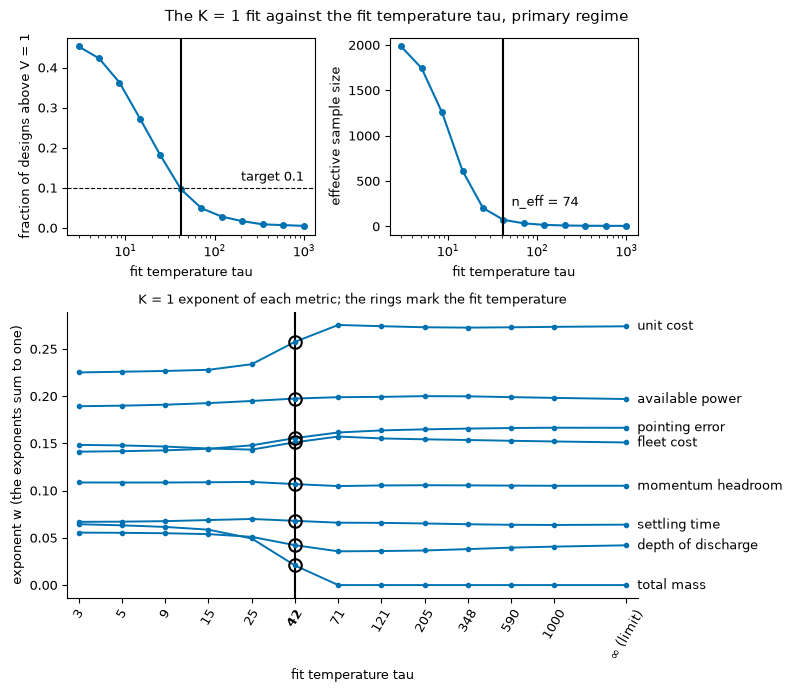

In [14]:
case.tau_sweep_lines_figure(study, fit)

:::{figure} #fig-tau-sweep
:label: fig-tau
The K = 1 fit against the fit temperature tau (the temperature of the soft maximum in the fit), primary regime (the dataset drawn with aggressive controller gains). Top: the fraction of designs above V = 1 (V is the invariant value; above 1 is beyond the fitted reference surface) with the target 0.1 (dashed), and the effective sample size with its value at the fit temperature. The vertical line is the fit temperature, the temperature at which the fraction is within 0.01 of the target (a convention, {numref}`Section %s <sect-methods>`). Bottom: the K = 1 exponent w of each metric against the temperature of the sweep (the axis lists the sweep's values, evenly spaced on a log scale, not to scale), one line per metric, the last position the tau = infinity limit; the exponents sum to one, and the rings mark the sweep point nearest the fit temperature, which is not the fit itself. Five metrics are at most 0.001 (the glossary's participation threshold) at every temperature and are not drawn. [full-size figure](figures/fig-tau-sweep.png)
:::


*Shows:* which metrics carry the K = 1 exponent at each fit temperature of the sweep and how each exponent moves with it; where the fit temperature sits on the fraction-above curve and what effective sample it leaves. *Does not show:* fit quality, the fitted reference surface or the designs near it, any K > 1 fit, the exponents' values at the fit temperature ({ref}`Appendix D.3 <sub-d-3>`), the metrics at most 0.001 throughout, or why a metric has no exponent (carried by another metric, or a step function of the swaps: the n-lemma reading is the text's). *Good for:* reading the n-lemma at the fit temperature and how far it depends on the temperature; seeing what the fit temperature costs in effective sample.

In [15]:
from generate_findings import temperature_sentence

temperature_sentence(study, fit)

'The fit temperature is tau = 41.7: a fraction 0.098 of designs lies above V = 1 (the target is 0.10), the band 1/tau is 0.0240 and the effective sample size is 73.6 designs. The effective sample size is the inverse sum of squares of the support weights, the softmax weights of the designs in the fit: the designs the soft maximum weighs as if equally, so the exponents at the fit temperature rest on about that many of the 2,134 designs. The contending set holds with the target fraction halved or doubled (<a href="supporting-material/#sub-d-5" target="_self" style="color:inherit;text-decoration:underline">Appendix D.5</a>). The robust scaler changes it: 8 metrics, 6 of the baseline\'s 7 among them, the largest exponent on total mass. The exponents\' stability under resampling of the rows is not assessed at K = 1: the movement of an exponent vector is read from K = 2 (<a href="supporting-material/#sub-d-15" target="_self" style="color:inherit;text-decoration:underline">Appendix D.15</a>).'

{numref}`Figure %s <fig-tau>` shows how the temperature is selected. Where the answer must be known, we plant it, with the generator of {ref}`Appendix C.7 <sub-c-7>`; the recovery of planted terms is read in {ref}`Appendix D.14 <sub-d-14>`.

In [16]:
from generate_findings import planted_sentence

planted_sentence()

'The worked example of <a href="supporting-material/#sub-c-7" target="_self" style="color:inherit;text-decoration:underline">Appendix C.7</a> has 900 rows, 4 metrics and 3 planted terms. The fit recovers all three terms on 16 of 20 such tables (Section 9, <a href="supporting-material/#sub-d-14" target="_self" style="color:inherit;text-decoration:underline">Appendix D.14</a>).'

(sect-case-analysis)=
## Case analysis

We read the case as the method asks: what contends, how, and where designs sit (the closing decision: {numref}`Table %s <tab-decision-case>`; tables: {ref}`Appendix D <appendix-d>`; digits that hold: {ref}`D.11 <sub-d-11>`).

In [17]:
from generate_findings import recovery_sentence

recovery_sentence()

'**A known answer.** On the 20 planted tables the fit recovers all three terms to within 0.05 in 16, at the exact maximum and at temperature 50; the 4 failures have 5, 5, 6 and 11 frontier rows on their thinnest term, where every recovered table has at least 18; the one with 11 is certified at temperature 50 and still errs by 0.20, with 0.68 of its frontier rows on the right term (<a href="supporting-material/#sub-d-14" target="_self" style="color:inherit;text-decoration:underline">Appendix D.14</a>).'

**One term.** At K = 1 the fit reports one tension at the balanced point ({numref}`Figure %s <fig-plane-1>`).

In [18]:
fit_case = fits[case.CASE_K]
band = fit.band  # the K = 1 band at every K (gap G-9)

In [19]:
from generate_findings import k1_sentence

k1_sentence(study, fit)

"At K = 1 the exact-maximum fit has a 7-lemma across controls, power and energy, plus cost: unit cost, available power, pointing error, fleet cost, momentum headroom, settling time and depth of discharge contend, with exponents at the fit temperature from 0.04 to 0.26. At the fit temperature total mass also carries 0.02 and is not in the contending set, which is the exact maximum's support (Definition 6). The exact-maximum optimum is one point, checked by a test of the repository on both regimes, so the support is not a solver's choice."

:::{figure} figures/fig-planes-k1.png
:label: fig-plane-1
Log-metric plane of the K = 1 fit (primary regime) in its two heaviest metrics, available power and unit cost; the slope of the line is their elasticity, the ratio of their exponents. The line is the surface, V = 1, in this plane. Each design is moved vertically by what its other eleven metrics add, weighed by their exponents, so that the line is the surface for every design: the distance below it is the design's level, log V divided by the unit-cost exponent, and a tenth of all designs lie above it, by the fit's convention.
:::

*Shows:* every design in the plane of the term's two heaviest metrics, adjusted for its other eleven, the term's line there, and each design's level as its distance from the line. *Does not show:* the other eleven metrics themselves, which the adjustment folds into the height, or the Pareto boundary. *Good for:* seeing the one-term trade-off as a line with a slope, and the line as the upper edge of the designs.

In [20]:
from generate_findings import choosing_k_sentence

choosing_k_sentence()

'**Two terms.** The package\'s checks for choosing K (<a href="supporting-material/#sub-d-15" target="_self" style="color:inherit;text-decoration:underline">Appendix D.15</a>) point to K = 2 on the primary regime and the stock regime, none deciding alone: the mean slack (in log V), read at the K = 1 temperature, drops most at K = 2 (0.08 and 0.05) and less at K = 3 (0.02 and 0.03), the largest drop read against the other two checks. The thinnest term holds 0.26 and 0.25 of the near-frontier designs at K = 2 and 0.06 and 0.06 at K = 3, the step where a thin term appears.'

At K = 2 the tension separates into two terms with different contending sets ({numref}`Figure %s <fig-chart-case>` and {numref}`Figure %s <fig-tensions-assoc>`); the margin, gap and status of this fit are in {numref}`Section %s <sect-results>` and {ref}`Appendix D.8 <sub-d-8>`.

In [21]:
from generate_findings import k_temperatures_sentence

k_temperatures_sentence(study, fits)

'Each K selects its own fit temperature by the same rule: tau = 42 and 113 at K = 1 and 2, with bands 1/tau of 0.0240 and 0.0088. The figures and the association reading use the K = 1 band at every K (gap G-9, <a href="supporting-material/#appendix-e" target="_self" style="color:inherit;text-decoration:underline">Appendix E</a>).'

:::{figure} figures/fig-chart-level.png
:label: fig-chart-case
The chart of the K = 2 fit, the K the package's checks point to ({ref}`Appendix D.15 <sub-d-15>`): each design's energy differential (log V of the $K=2$ fit, the level) against its position along the surface. The position is measured along the direction in which the near-frontier designs spread the most, the first principal direction of the near-frontier chart of the K = 1 fit. It is a reading of the sampled designs and not part of the model ({ref}`Appendix D.16 <sub-d-16>` gives its share of the spread and its loadings; the axis names the metrics it improves). The surface is the flat line log V = 0 whatever the position, by construction; about a tenth of the designs lie above it, the fit's convention; grey: the near-frontier band; a design above the line lies beyond the surface (V > 1) and one below it inside (V < 1).
:::

*Shows:* each design's level against its position along the direction of most spread, the surface as the flat line log V = 0; where along that direction the designs reach the surface and where they fall deepest inside. *Does not show:* terms, any grouping, or the other directions of position. *Good for:* reading a design's level apart from where it sits along the main trade-off.

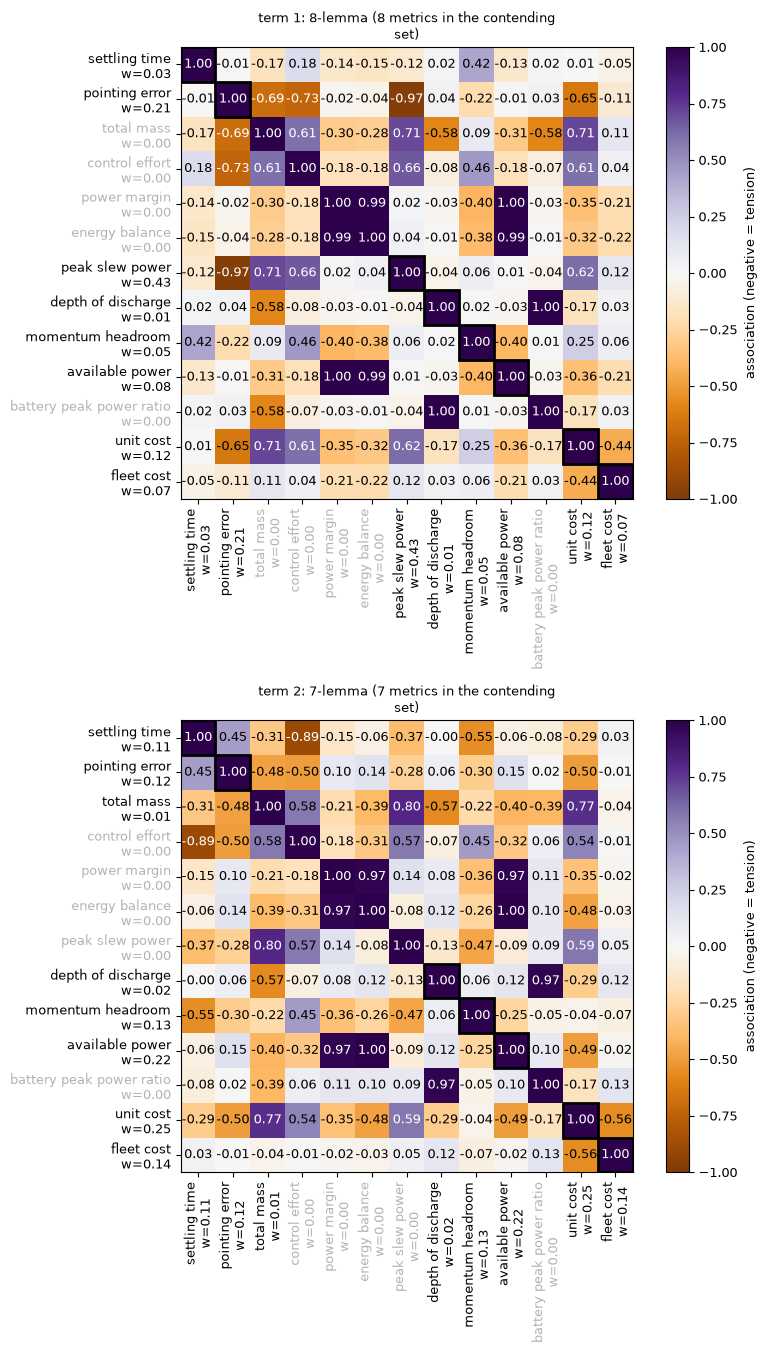

In [22]:
case.tension_figure(study, fit_case, band=band)

:::{figure} #fig-tensions-case
:label: fig-tensions-assoc
Association (the Pearson correlation of the log-metrics) among the near-frontier designs assigned to each term of the K = 2 fit (its cell), an analysis of those designs and not of the model (negative: tension). Outlined: the contending set, the support of the exact-maximum fit. A near-collinear pair is one axis, and {ref}`Appendix D.3 <sub-d-3>` reads its exponents summed. At K = 1 peak slew power carries no exponent; here it leads term 1. Here w is the exponent at the fit temperature, grey below the participation threshold, so an outlined metric can be grey and a black one not outlined. A term with fewer than ten near-frontier designs is drawn without cells, and a line in its panel gives the count: too few designs for a correlation. [full-size figure](figures/fig-tensions-case.png)
:::


*Shows:* which metrics trade on each term with enough near-frontier designs, and each term's contending set with its exponents. *Does not show:* causation, the exponents' uncertainty, designs. *Good for:* naming what trades against what on each term.

In [23]:
from generate_findings import terms_sentence

terms_sentence(study, fits)

'The K = 2 terms have contending sets (exact-maximum supports) of 8 and 7 metrics; peak slew power, absent from the K = 1 set, leads term 1. The term shares are 0.74 and 0.26 for terms 1 and 2 (<a href="supporting-material/#sub-d-3" target="_self" style="color:inherit;text-decoration:underline">Appendix D.3</a>).'

A clustering with per-cluster correlations would describe the same designs. The terms add a model: each term's fitted exponents give the elasticities at which its contending metrics trade ({prf:ref}`thm-elasticity`) and a level against which every design is read. The association figures are an analysis of each cell's designs.

In [24]:
from generate_findings import elasticity_sentence

elasticity_sentence(study, fits)

"On term 2 the elasticity between unit cost and available power is -0.9: along the term, one percent gained in available power is 0.9 percent given up in unit cost. The percentages are of the conditioned metrics (their logs after the standard scaler); Theorem 7 gives the rates in the attributes' own units, where the rate between two metrics is multiplied by alpha_i/alpha_j, the ratio of their conditioning exponents. Term 1's two leading metrics, peak slew power and pointing error, are stepped by the swaps of the tracker grade and the wheel class, so its elasticity is read across the swapped parts' alternatives rather than along one continuous trade."

**Three metrics at a time.** {numref}`Figure %s <fig-ternary-pair>` shows the fit on two triples of the primary regime's metrics as triangles. A design sits at its shares of the triple's total (each metric in units of its geometric mean over the table, the three then summed), a corner being all of the total in one metric, where that metric alone raises V and nothing trades; a numbered marker is a term's exponent vector, and a region is where that term is the largest.

:::{figure} figures/fig-ternary-pair.png
:label: fig-ternary-pair
Two triples of the primary regime's metrics, each fitted with its own two terms (a corner "favours" a metric where that metric's share of the triple's total is largest, and a region's label names its leading pair where the third exponent is small): in A one region trades pointing error against control effort and the other region total mass against pointing error; in B one region trades settling time against control effort and the other region is depth of discharge alone. The fits are not the case's K = 2 fit; the triples were picked from the 56 triples of eight of the thirteen metrics, searched at one, two and three terms in each regime, where 105 of the 291 fits that could be made had at least two stable terms that contend differently.
:::

*Shows:* where each term leads and where its V peaks. *Does not show:* groups of designs, the values of V on the lines, the other ten metrics or a cause.

**Two regimes.** The same pipeline on the baseline regime, whose gains were sampled over a lower range ({ref}`Appendix C.1 <sub-c-1>`), separates the problem's contribution from the gains' ({ref}`Appendix D.4 <sub-d-4>`). {prf:ref}`thm-convex` gives convexity, not strict convexity. For two metrics with identical columns the objective is flat along their swap, so which of a pair that nearly coincides carries the exponent is not read as a finding. The sets are compared with such a pair counted as one (its exponents are still read apart, {ref}`Appendix D.3 <sub-d-3>`).

In [25]:
from generate_findings import regime_sentence

regime_sentence()

'The regimes return a 7-lemma and an 8-lemma sharing 7 metrics (available power, depth of discharge, fleet cost, momentum headroom, pointing error, settling time and unit cost); the primary set lies inside the stock set, which adds total mass. The stock set spans controls, power and energy, mass, plus cost: mass enters only in the stock regime.'

**Propose, predict, check** is a check of the regressor on a few proposals, not an estimate of a rate. A regressor from configuration to chart coordinates predicts where proposals fall; we then measure them ({ref}`Appendix D.10 <sub-d-10>`). A proposal is the pooled configuration predicted nearest a hole of the four-metric chart, within a radius that a stated rule sets from the data: the 2nd percentile of the pool's nearest predicted distances to the 300 most isolated holes. Turning a predicted level into a bounded outcome is the analyst's task and can fail while the fit is certified: a prediction outside the quantity's admissible range is reported as invalid, never clipped. The proposals fail the depth-of-discharge feasibility condition: they reached the four-metric fitted reference surface by spending the battery (the Discussion's reading of the check, {numref}`Section %s <sect-discussion>`).

In [26]:
reg = case.fit_regressor(study)

In [27]:
pc = case.predict_check(study, reg)

In [28]:
from generate_findings import predict_check_sentence

predict_check_sentence(pc, reg)

"Of 3 proposals, the predicted energy differential lies within the regressor's own band 1/tau = 0.0935 (its four-metric fit's, not the case's) of the measured one for 3, and the predicted position within that band for 3; position errors run from 0.2 to 0.8 bands."

In [29]:
from generate_findings import decision

dec = decision(study, fits)

In [30]:
from generate_findings import decision_sentence

decision_sentence(dec)

'**What the executives decide.** The case\'s two stakeholders: the operator cares about the pointing error, the sponsor about the unit cost and the fleet cost. The requirements and the fits cut 2,134 feasible designs to 28 that pass all six requirements and lie in the near-frontier band of both fits, the simpler and the richer (the K = 1 band for both, as at every K; <a href="supporting-material/#sub-d-19" target="_self" style="color:inherit;text-decoration:underline">Appendix D.19</a>). One question remains, and it is theirs: whether a fine star tracker, which brings the pointing error from about 0.003 to 0.0008 degree, is worth about 0.56 M USD of a 6 M USD fleet cost limit. The fleets differ in wheel class, tracker grade and fleet size, so that cost is theirs, not the tracker\'s. If it is, the fleet of 5 medium-wheel, fine-tracker satellites at 1.69 M USD (337,000 USD each) is the one whose larger shortfall on the two measures, each scaled from its best to its worst of the 28, is smallest, among the 5 that no other beats on both; if not, the fleet of 4 small-wheel, medium-tracker satellites at 1.13 M USD is the cheapest fleet. The method prices the question and does not answer it; the numbers are nominal (<a href="supporting-material/#sub-c-8" target="_self" style="color:inherit;text-decoration:underline">Appendix C.8</a>).'

In [31]:
from generate_findings import decision_table

decision_table(dec)

rule,configuration,pointing error (degree),unit cost (USD),fleet cost (USD),level
baseline configuration,"medium wheel, medium tracker, fleet 1",0.01553,"461,360","461,360",-0.330
sponsor alone,"small wheel, medium tracker, fleet 4",0.00295,"281,866","1,127,465",+0.016
operator alone,"medium wheel, fine tracker, fleet 6",0.00074,"343,961","2,063,765",+0.010
between them,"medium wheel, fine tracker, fleet 5",0.00080,"337,228","1,686,142",-0.012
balanced between the terms,"medium wheel, medium tracker, fleet 6",0.00282,"266,193","1,597,160",-0.017
cheapest unit cost,"medium wheel, medium tracker, fleet 25",0.00280,"233,852","5,846,300",-0.022


::::{table} The baseline configuration and the designs the rules pick, with the executives' measures (the operator's pointing error, the sponsor's unit cost and fleet cost) and the level of each (log V at K = 2, positive beyond the fitted reference surface). The rows show wheel, tracker and fleet only; the picks' other design variables (panel span, battery capacity, the gains) are in {ref}`Appendix D.19 <sub-d-19>`. The rows follow the order of the rules, and the levels, all inside the near-frontier band, do not rank them. Balanced between the terms is the design whose two K = 2 term levels are closest. The last two rows are context: the cheapest unit needs the largest fleet. The method does not tell the schedule or the risk, what to buy beyond the modelled parts, or what a larger fleet is worth. The shortlist and the rules are in {ref}`Appendix D.19 <sub-d-19>`.
:label: tab-decision-case
:::{embed} #tab-decision
:remove-input: true
:::
::::

(sect-discussion)=
## Discussion

**Interpretation is human validation.** The fit reports what contends; whether that is an explicable trade-off is for an engineer to decide. The exponents and elasticities are features of the conditioned empirical model: they describe how the sampled designs trade, and not a causal exchange that changing a variable would reproduce. A hole in the chart is an opportunity only where the trade space is log-convex around it, which the data cannot prove. Novelty $V-1$ says how far beyond the fitted reference surface a design lies, not whether anyone wants it.

**Verify and validate.** Machine verification shows that a formula follows from its hypotheses and that the code agrees; it does not show that the hypotheses suit a table. That is human validation, which remains for a human: the conditioning, the choice of K and the reading of every finding. {ref}`Appendix B <appendix-b>` gives one line of code to read each proof step against; it cannot say that a sentence means what its line computes.

**Three claims.** The certificate covers this: for a sharp fit, a local minimizer with the cells held fixed ({prf:ref}`cor-bound` at the returned point, {prf:ref}`prop-local` at the exact minimizers it approximates); for a soft fit, a strict local minimizer at a point where the first-order conditions hold exactly ({prf:ref}`thm-certificate`). That the surface describes the observed designs is a claim about this table, read from its figures. That the fit holds for designs outside the table, or supports a decision, is a third claim the certificate does not make: it needs its own validation.

**Requirements after the fit.** Fitting first and reading the requirements after is the unconstrained-then-constrained reading of a trade study. **Numerical.** {ref}`Appendix D.17 <sub-d-17>` prices each of the six requirements read after the fit at the fitted reference surface and counts the near-frontier designs it excludes.

In [32]:
from generate_findings import design_sets_sentence

design_sets_sentence()

'With every design set conditioned as the fit of record is, removing the infeasible designs or imposing the four performance thresholds before the fit leaves the one-term contending set of the primary regime (seven metrics) unchanged and changes that of the baseline regime by at most two of its eight metrics (<a href="supporting-material/#sub-d-17" target="_self" style="color:inherit;text-decoration:underline">Appendix D.17</a>).'

In [33]:
from generate_findings import predict_reading

predict_reading(pc, reg)

"**What propose, predict, check showed.** Two of the three proposals are one configuration. It showed that the regressor's predicted energy differential and predicted position of a proposal each lie within its band of the measured one (3 of 3 and 3 of 3): the error of the prediction. Where the proposals landed is a second quantity, the measured log V against zero. They reached the four-metric fitted reference surface they were aimed at by spending the battery. Their measured log V is within 0.164 of V = 1, against the band 0.094. Their batteries are 22 Wh, at the bottom of the 20 to 200 Wh range, and all 3 fail the model's depth-of-discharge feasibility condition at 0.39. The proposer's chart is the four-metric view, which has no depth-of-discharge axis. A proposer that also predicts the feasibility flags, and proposes only designs predicted to meet them, is future work. Three proposals of two designs illustrate and do not estimate a rate. A predicted crossing of V = 1 remains a hypothesis."

**Why a surface.** An answer far from the fitted reference surface is hard to justify, and the analysis must rerun on empirical data to support configuration management.

**Cross-application.** The input is a table of configurations and attributes. How the attributes were produced is a black box to the method, so the same functions serve a simulator, a physical test campaign or a human assessment.

**Limits, in brief.** The fitted reference surface is log-convex. One term is tangent at one place and is conservative off it. The exponents depend on the conditioning. Small samples determine exponents weakly. Designed samples, such as grids, are not independent observations: the exponents describe the sample and are not estimates with a sampling error. {ref}`Appendix E <appendix-e>` gives the ledger.

**Tensions beyond the first, and PCA.** K = 1 finds one tension; several regional tensions need K > 1. A search for successive tensions, each found after removing the last, as PCA extracts components, is a research question: we claim neither that it works nor that tensions are orthogonal. Tensions the sampling never exercised cannot appear.

**Novelty and white space.** By {prf:ref}`thm-invariant`, a design with $V=v$ is a design on the fitted reference surface scaled by $v$, so $V-1$ is a relative improvement, meaningful against the band $1/\tau$.

**The kernel direction.** The research question is which kernel expansions keep the fit a geometric program in the exponents and the model a generalized geometric program in the metrics, so that the guarantees and reading rules carry over. Nothing here is built.

(sect-reproducibility)=
## Reproducibility and your own case

Every figure, table and reported number comes from a call into a tested module. {ref}`Appendix F <appendix-f>` gives the pinned toolchain, the environment of record, the commands and one row per item. To run your own table, supply configurations, attributes and a conditioning rule, and use the same calls. The docsite's Getting started page is where to begin.

(sect-future)=
## Future work and final remark

Beyond one term, K > 1 is built; beyond sharp weights, a nonsmooth search on the tangent cones of the ridges. Beyond the analyst's K, selection rules. Beyond small K, scalability and speed, and a global search or certificate for the alternation (Q1). Beyond log-affine conditioning, kernels that keep the model a generalized geometric program (GGP) in the metrics. Beyond continuous variables within a category, discrete design variables. Beyond a log-convex surface, the detection of dents and holes. Beyond illustrative hardware values, datasheet values. Beyond pencil-and-paper checks, the Lean theorem prover, starting with the log-mean-exp bounds and the convexity of the fit objective. A proof over the reals backs the mathematics, not the floating-point computation, which the certificates check. Beyond Python, a Rust core compiled to WebAssembly, whose verification tools address crashes and overflow, not numerical accuracy.

**Final remark.** A forecast $V$ for a new capability or technology entering the design space would say how far beyond the fitted reference surface it lies, a relative improvement against the band ({numref}`Section %s <sect-discussion>`), not whether anyone wants it.

(sect-process)=
## Acknowledgments and process

Work was done in supervisor-gated work packages: a written scope the author approved before execution, and a review afterwards. AI coding assistance (Claude Code, Anthropic) drafted code, derivation scripts and text inside those packages, in a process modelled on the harness described in [@zargham2026incose]. Its deterministic checks and named human approver are the verification mechanism this paper inherits. The derivations are machine-checked. The author takes responsibility.

(sect-cited)=
## Works cited

The list holds the sources of the main text and of the register of {ref}`Appendix G <appendix-g>`.

```{bibliography}
```